In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load preprocessed training and testing datasets

train_url = "https://raw.githubusercontent.com/revathi9925/SWYNEX-Dataset-Exploration-Preprocessing/main/titanic_train_preprocessed.csv"

test_url = "https://raw.githubusercontent.com/revathi9925/SWYNEX-Dataset-Exploration-Preprocessing/main/titanic_test_preprocessed.csv"

train_df = pd.read_csv(train_url)
test_df = pd.read_csv(test_url)

print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

display(train_df.head())

Training Dataset Shape: (712, 15)
Testing Dataset Shape: (179, 15)


,num__age,num__fare,num__sibsp,num__parch,cat__sex_female,cat__sex_male,cat__class_First,cat__class_Second,cat__class_Third,cat__embarked_C,cat__embarked_Q,cat__embarked_S,cat__alone_False,cat__alone_True,survived
0,-0.081135,0.513812,-0.465084,-0.466183,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1
1,-0.081135,-0.662563,-0.465084,-0.466183,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0
2,-0.081135,3.955399,-0.465084,-0.466183,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0
3,-0.887827,-0.467874,-0.465084,0.727782,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,1
4,0.110934,-0.115977,0.478335,0.727782,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1


In [3]:
# Separate training features and target
X_train = train_df.drop("survived", axis=1)
y_train = train_df["survived"]

# Separate testing features and target
X_test = test_df.drop("survived", axis=1)
y_test = test_df["survived"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 14)
X_test: (179, 14)
y_train: (712,)
y_test: (179,)


In [4]:
# Create Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# Train the model
log_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [5]:
# Predict passenger survival
log_predictions = log_model.predict(X_test)

# Display first 10 predictions
print("Predicted Values:")
print(log_predictions[:10])

print("\nActual Values:")
print(y_test.values[:10])

Predicted Values:
[0 0 0 0 1 1 1 0 0 0]

Actual Values:
[0 0 1 0 1 1 1 0 0 0]


In [6]:
# Calculate evaluation metrics
log_accuracy = accuracy_score(y_test, log_predictions)

log_precision = precision_score(y_test, log_predictions)

log_recall = recall_score(y_test, log_predictions)

log_f1 = f1_score(y_test, log_predictions)

log_auc = roc_auc_score(
    y_test,
    log_model.predict_proba(X_test)[:, 1]
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(log_accuracy, 4))
print("Precision:", round(log_precision, 4))
print("Recall:", round(log_recall, 4))
print("F1 Score:", round(log_f1, 4))
print("ROC-AUC:", round(log_auc, 4))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.8156
Precision: 0.8103
Recall: 0.6812
F1 Score: 0.7402
ROC-AUC: 0.8498


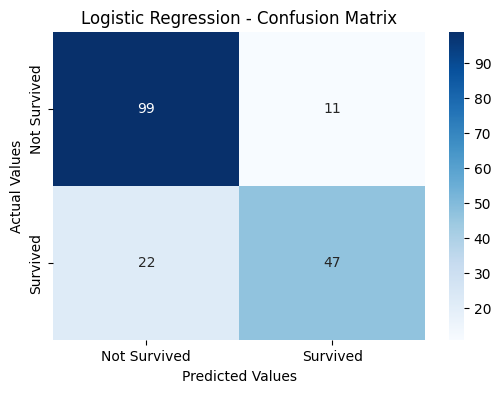

In [7]:
# Create confusion matrix
cm = confusion_matrix(y_test, log_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [8]:
print("Classification Report:")
print(classification_report(y_test, log_predictions))

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       110
           1       0.81      0.68      0.74        69

    accuracy                           0.82       179
   macro avg       0.81      0.79      0.80       179
weighted avg       0.82      0.82      0.81       179



In [9]:
# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [10]:
# Predict passenger survival
rf_predictions = rf_model.predict(X_test)

print("Predicted Values:")
print(rf_predictions[:10])

print("\nActual Values:")
print(y_test.values[:10])

Predicted Values:
[0 0 0 0 1 0 1 1 0 0]

Actual Values:
[0 0 1 0 1 1 1 0 0 0]


In [11]:
# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_predictions)

rf_precision = precision_score(y_test, rf_predictions)

rf_recall = recall_score(y_test, rf_predictions)

rf_f1 = f1_score(y_test, rf_predictions)

rf_auc = roc_auc_score(
    y_test,
    rf_model.predict_proba(X_test)[:, 1]
)

print("RANDOM FOREST RESULTS")
print("---------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1 Score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_auc, 4))

RANDOM FOREST RESULTS
---------------------
Accuracy: 0.8045
Precision: 0.7576
Recall: 0.7246
F1 Score: 0.7407
ROC-AUC: 0.8238


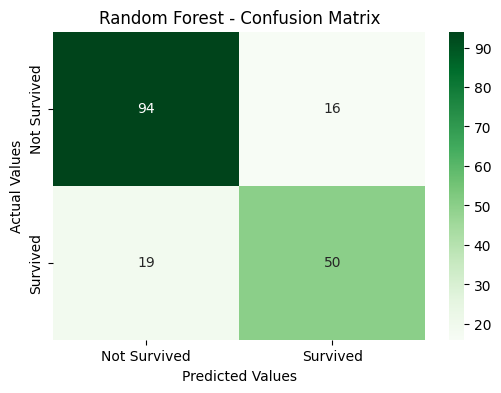

In [12]:
cm_rf = confusion_matrix(y_test, rf_predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [13]:
print("Random Forest Classification Report:")
print(classification_report(y_test, rf_predictions))

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.85      0.84       110
           1       0.76      0.72      0.74        69

    accuracy                           0.80       179
   macro avg       0.79      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



In [14]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [log_accuracy, rf_accuracy],
    "Precision": [log_precision, rf_precision],
    "Recall": [log_recall, rf_recall],
    "F1 Score": [log_f1, rf_f1],
    "ROC-AUC": [log_auc, rf_auc]
})

print(comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.8156     0.8103  0.6812    0.7402   0.8498
1        Random Forest    0.8045     0.7576  0.7246    0.7407   0.8238


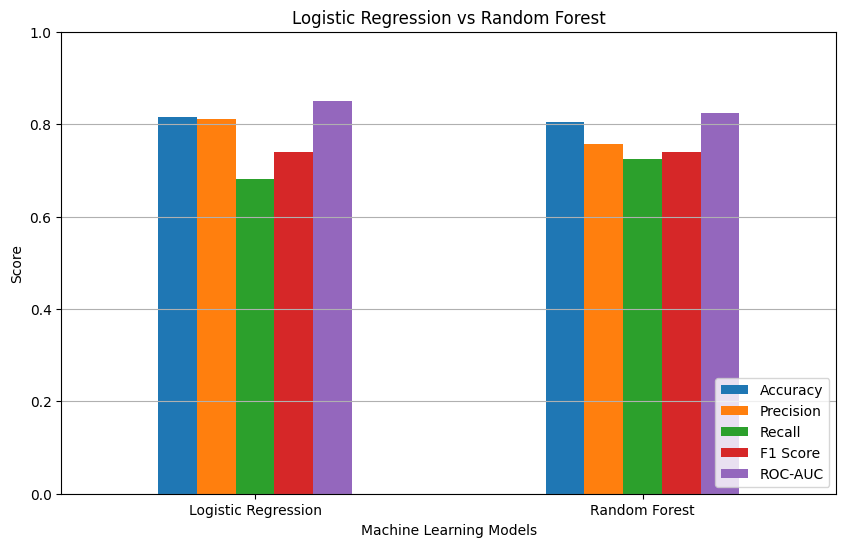

In [15]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(kind="bar", figsize=(10, 6))

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

In [16]:
best_model = comparison.loc[
    comparison["F1 Score"].idxmax(), "Model"
]

print("Best Model based on F1 Score:", best_model)

Best Model based on F1 Score: Random Forest


In [17]:
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [log_accuracy, rf_accuracy],
    "Precision": [log_precision, rf_precision],
    "Recall": [log_recall, rf_recall],
    "F1 Score": [log_f1, rf_f1],
    "ROC-AUC": [log_auc, rf_auc]
})

print(comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.8156     0.8103  0.6812    0.7402   0.8498
1        Random Forest    0.8045     0.7576  0.7246    0.7407   0.8238


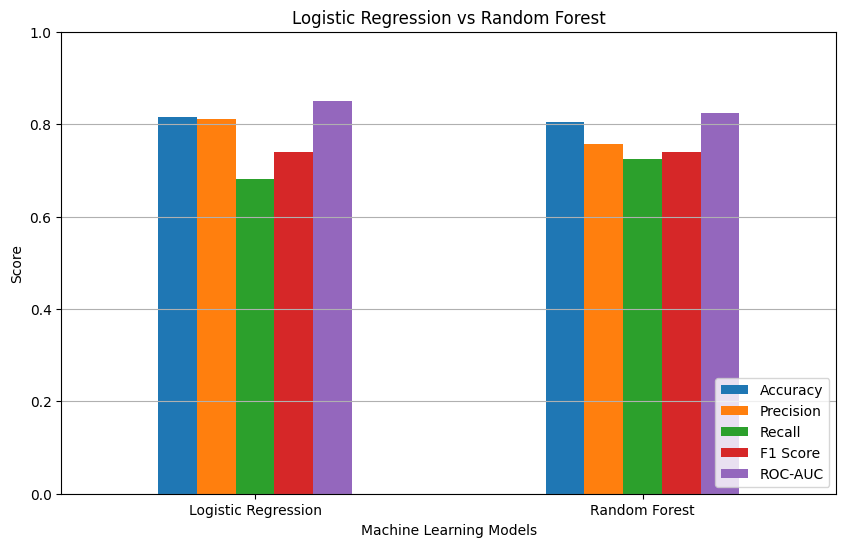

In [18]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

In [19]:
best_model = comparison.loc[
    comparison["F1 Score"].idxmax(), "Model"
]

print("Best Model based on F1 Score:", best_model)

Best Model based on F1 Score: Random Forest


## Final Conclusion

In this project, two machine learning algorithms, Logistic Regression and Random Forest Classifier, were trained and evaluated using the Titanic dataset.

Both models were evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC metrics.

Logistic Regression achieved better accuracy, precision and ROC-AUC, whereas Random Forest achieved better recall. Both models showed nearly equal F1-scores.

Based on the overall performance, Logistic Regression demonstrated slightly better results for this dataset. However, Random Forest was better at identifying actual survivors.

This project helped me understand model training, prediction, evaluation and comparison of different machine learning algorithms.